### Import libraries and configure project paths

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid")

cwd = Path.cwd().resolve()

if (cwd / "data" / "raw").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot locate data/raw. Open the project folder in VS Code."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder:", DATA_DIR)
print("Python environment ready!")

Project root: E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research
Data folder: E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research\data\raw
Python environment ready!


### Verify the three dataset files

In [2]:
required_files = {
    "features": "elliptic_txs_features.csv",
    "classes": "elliptic_txs_classes.csv",
    "edges": "elliptic_txs_edgelist.csv"
}

for name, filename in required_files.items():
    path = DATA_DIR / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"FOUND: {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING: {filename}")

missing = [
    filename
    for filename in required_files.values()
    if not (DATA_DIR / filename).exists()
]

if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

print("\nAll dataset files found successfully!")

FOUND: elliptic_txs_features.csv (657.73 MB)
FOUND: elliptic_txs_classes.csv (3.15 MB)
FOUND: elliptic_txs_edgelist.csv (4.26 MB)

All dataset files found successfully!


### Load the real Elliptic dataset

In [ ]:
features_path = DATA_DIR / required_files["features"]
classes_path = DATA_DIR / required_files["classes"]
edges_path = DATA_DIR / required_files["edges"]

# Load headerless features file.
features = pd.read_csv(
    features_path,
    header=None,
    dtype={0: "string"},
    low_memory=False
)


num_features = features.shape[1] - 2

features.columns = (
    ["txId", "time_step"]
    + [f"feature_{i}" for i in range(1, num_features + 1)]
)

# Load files with their original headers.
classes = pd.read_csv(
    classes_path,
    dtype={"txId": "string"}
)

edges = pd.read_csv(
    edges_path,
    dtype={"txId1": "string", "txId2": "string"}
)

# Clean header whitespace, if present.
classes.columns = classes.columns.str.strip()
edges.columns = edges.columns.str.strip()

# Remove whitespace from identifiers.
features["txId"] = features["txId"].str.strip()
classes["txId"] = classes["txId"].str.strip()
edges["txId1"] = edges["txId1"].str.strip()
edges["txId2"] = edges["txId2"].str.strip()

features["time_step"] = pd.to_numeric(
    features["time_step"], errors="raise"
).astype(int)

classes["class"] = classes["class"].astype("string").str.strip()

print("DATASET LOADED SUCCESSFULLY")
print("-" * 45)

print("Features shape:", features.shape)
print("Classes shape:", classes.shape)
print("Edges shape:", edges.shape)

print("\nNumber of anonymized features:", num_features)
print("Time steps:", features["time_step"].nunique())

DATASET LOADED SUCCESSFULLY
---------------------------------------------
Features shape: (203769, 167)
Classes shape: (203769, 2)
Edges shape: (234355, 2)

Number of anonymized features: 165
Time steps: 49


### Inspect the dataset

In [4]:
print("FIRST 5 FEATURE RECORDS")
display(features.iloc[:5, :10])

print("\nFIRST 5 CLASS RECORDS")
display(classes.head())

print("\nFIRST 5 EDGE RECORDS")
display(edges.head())

print("\nFEATURE DATA TYPES")
display(features.dtypes.value_counts())

print("\nFEATURE DATASET INFORMATION")
features.info()

FIRST 5 FEATURE RECORDS


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523



FIRST 5 CLASS RECORDS


,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown



FIRST 5 EDGE RECORDS


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206



FEATURE DATA TYPES


float64    165
string       1
int64        1
Name: count, dtype: int64


FEATURE DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 203769 entries, 0 to 203768
Columns: 167 entries, txId to feature_165
dtypes: float64(165), int64(1), string(1)
memory usage: 259.6 MB


### Validate transaction identifiers and connections

In [5]:
print("DATA QUALITY CHECK")
print("=" * 50)

print("Duplicate feature IDs:",
      features["txId"].duplicated().sum())

print("Duplicate class IDs:",
      classes["txId"].duplicated().sum())

print("Missing feature IDs:",
      features["txId"].isna().sum())

print("Missing class IDs:",
      classes["txId"].isna().sum())

print("Missing edge endpoints:",
      edges[["txId1", "txId2"]].isna().sum().sum())

print("Duplicate directed edges:",
      edges.duplicated().sum())

print("Self-loop edges:",
      (edges["txId1"] == edges["txId2"]).sum())

node_ids = set(features["txId"])

missing_source_nodes = (
    ~edges["txId1"].isin(node_ids)
).sum()

missing_target_nodes = (
    ~edges["txId2"].isin(node_ids)
).sum()

print("Edge sources missing from features:",
      missing_source_nodes)

print("Edge targets missing from features:",
      missing_target_nodes)

class_ids = set(classes["txId"])

print("Feature IDs without class records:",
      (~features["txId"].isin(class_ids)).sum())

print("Class IDs without feature records:",
      (~classes["txId"].isin(node_ids)).sum())

DATA QUALITY CHECK
Duplicate feature IDs: 0
Duplicate class IDs: 0
Missing feature IDs: 0
Missing class IDs: 0
Missing edge endpoints: 0
Duplicate directed edges: 0
Self-loop edges: 0
Edge sources missing from features: 0
Edge targets missing from features: 0
Feature IDs without class records: 0
Class IDs without feature records: 0


### Merge features with class labels

In [6]:
if features["txId"].duplicated().any():
    raise ValueError("Duplicate transaction IDs in features file.")

if classes["txId"].duplicated().any():
    raise ValueError("Duplicate transaction IDs in classes file.")

df = features.merge(
    classes,
    on="txId",
    how="left",
    validate="one_to_one"
)

class_mapping = {
    "1": "Illicit",
    "2": "Licit",
    "unknown": "Unknown"
}

df["class_name"] = df["class"].map(class_mapping)

print("Merged dataset shape:", df.shape)

print("\nClass distribution:")
print(df["class_name"].value_counts(dropna=False))

print("\nFirst five merged records:")
display(
    df[
        ["txId", "time_step", "class", "class_name"]
    ].head()
)

Merged dataset shape: (203769, 169)

Class distribution:
class_name
Unknown    157205
Licit       42019
Illicit      4545
Name: count, dtype: int64

First five merged records:


C:\Users\rayan\AppData\Local\Temp\ipykernel_19700\722671699.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["class_name"] = df["class"].map(class_mapping)


,txId,time_step,class,class_name
0,230425980,1,unknown,Unknown
1,5530458,1,unknown,Unknown
2,232022460,1,unknown,Unknown
3,232438397,1,2,Licit
4,230460314,1,unknown,Unknown


### Calculate dataset statistics

In [7]:
total_transactions = len(df)
total_edges = len(edges)

class_counts = df["class_name"].value_counts()

illicit_count = class_counts.get("Illicit", 0)
licit_count = class_counts.get("Licit", 0)
unknown_count = class_counts.get("Unknown", 0)

known_count = illicit_count + licit_count

print("ELLIPTIC DATASET SUMMARY")
print("=" * 50)

print(f"Total transactions: {total_transactions:,}")
print(f"Total directed edges: {total_edges:,}")
print(f"Number of time steps: {df['time_step'].nunique()}")
print(f"Number of anonymized features: {num_features}")

print(f"\nIllicit transactions: {illicit_count:,}")
print(f"Licit transactions: {licit_count:,}")
print(f"Unknown transactions: {unknown_count:,}")

print(f"\nKnown labeled transactions: {known_count:,}")

if known_count > 0:
    print(
        f"Illicit percentage among labeled: "
        f"{illicit_count / known_count * 100:.2f}%"
    )

print(
    f"Unknown percentage overall: "
    f"{unknown_count / total_transactions * 100:.2f}%"
)

ELLIPTIC DATASET SUMMARY
Total transactions: 203,769
Total directed edges: 234,355
Number of time steps: 49
Number of anonymized features: 165

Illicit transactions: 4,545
Licit transactions: 42,019
Unknown transactions: 157,205

Known labeled transactions: 46,564
Illicit percentage among labeled: 9.76%
Unknown percentage overall: 77.15%


### Visualize class distribution

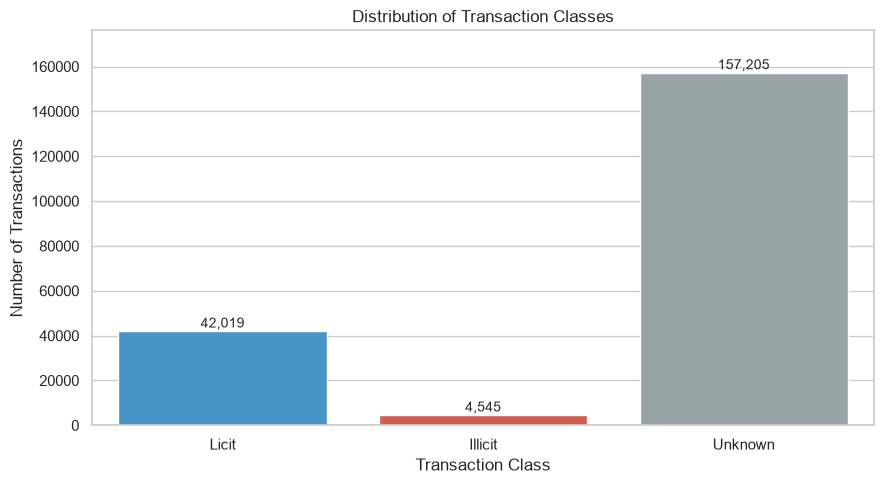

In [8]:
class_order = ["Licit", "Illicit", "Unknown"]

counts = (
    df["class_name"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=counts.index,
    y=counts.values,
    hue=counts.index,
    palette=["#3498db", "#e74c3c", "#95a5a6"],
    legend=False
)

for i, count in enumerate(counts.values):
    ax.text(
        i,
        count + max(counts.values) * 0.01,
        f"{count:,}",
        ha="center",
        fontsize=10
    )

plt.title("Distribution of Transaction Classes")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.ylim(0, max(counts.values) * 1.12)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Analyze transaction activity across time

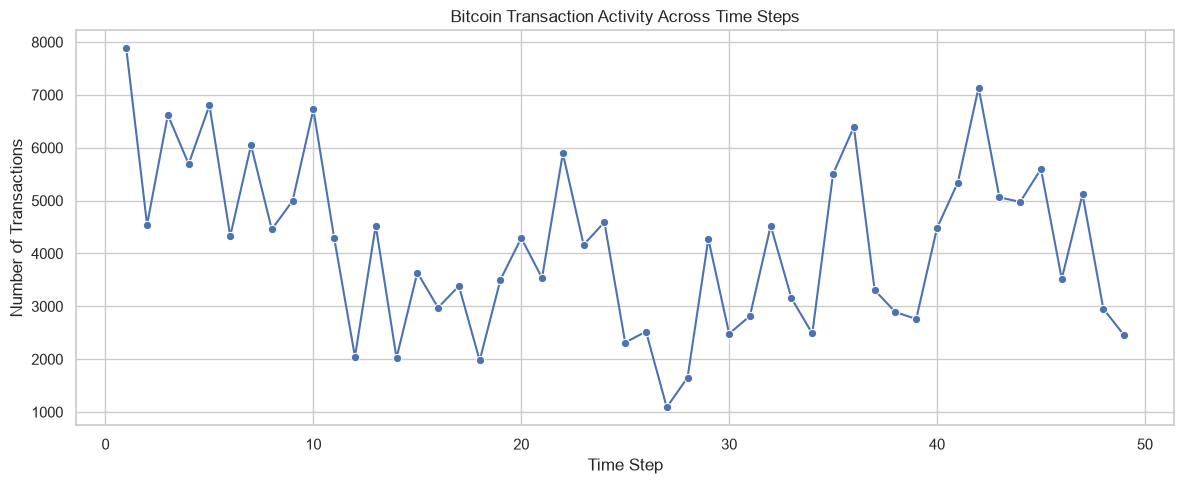

,time_step,transaction_count
0,1,7880
1,2,4544
2,3,6621
3,4,5693
4,5,6803
5,6,4328
6,7,6048
7,8,4457
8,9,4996
9,10,6727


In [9]:
time_counts = (
    df.groupby("time_step")
    .size()
    .reset_index(name="transaction_count")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=time_counts,
    x="time_step",
    y="transaction_count",
    marker="o"
)

plt.title("Bitcoin Transaction Activity Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_transactions_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(time_counts.head(10))

### Analyze illicit and licit transactions over time

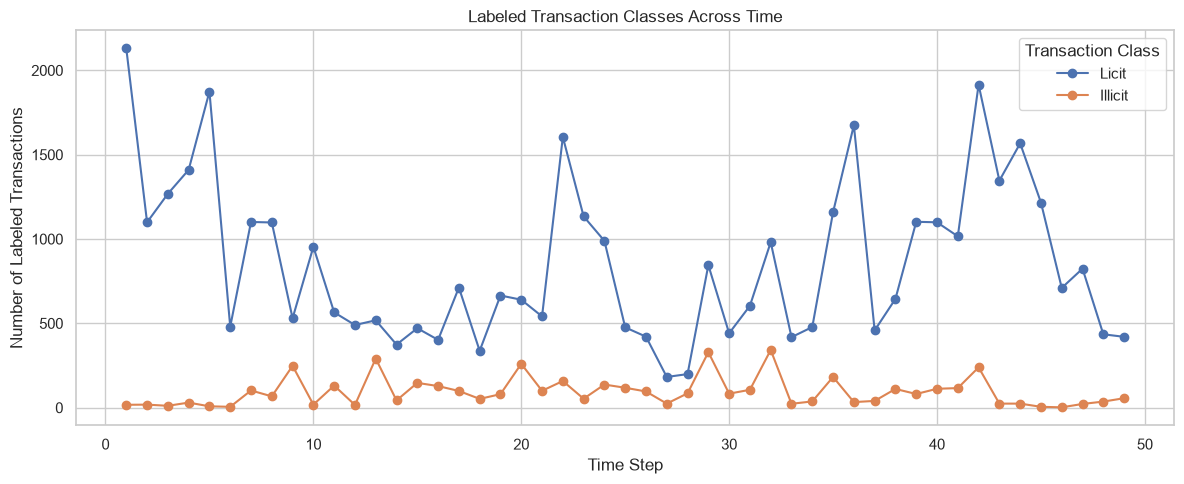

class_name,Licit,Illicit
time_step,,
1,2130,17
2,1099,18
3,1268,11
4,1410,30
5,1874,8
6,480,5
7,1101,102
8,1098,67
9,530,248


In [10]:
known_df = df[
    df["class_name"].isin(["Illicit", "Licit"])
].copy()

temporal_classes = (
    known_df.groupby(["time_step", "class_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Licit", "Illicit"], fill_value=0)
)

temporal_classes.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Labeled Transaction Classes Across Time")
plt.xlabel("Time Step")
plt.ylabel("Number of Labeled Transactions")
plt.legend(title="Transaction Class")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_class_distribution_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(temporal_classes.head(10))

### Analyze illicit transaction percentage

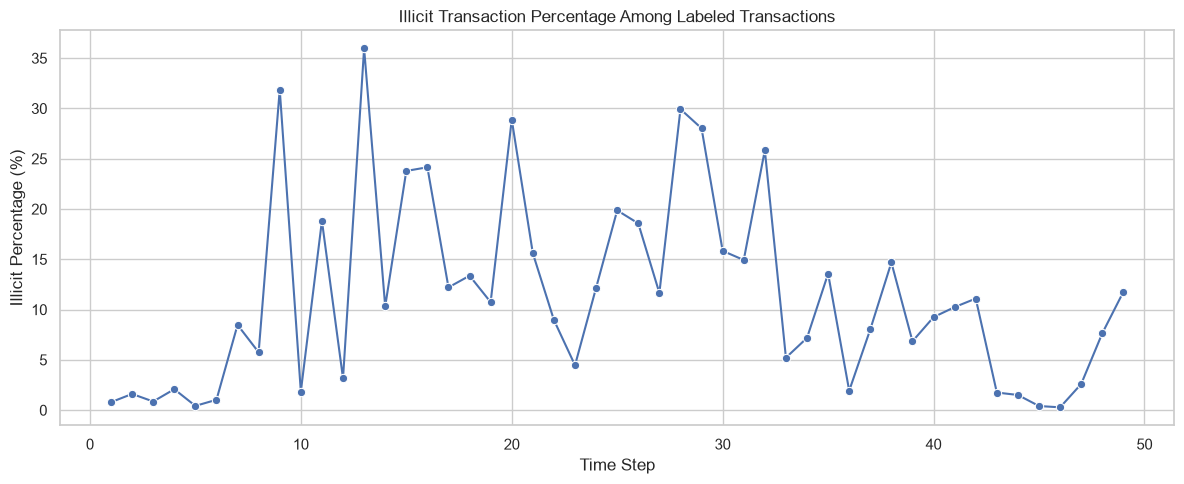

class_name,total_labeled,illicit_percentage
count,49.000000,49.000000
mean,950.285714,11.347647
std,479.874810,9.489042
min,206.000000,0.280899
25%,524.000000,2.600473
50%,811.000000,10.247350
75%,1211.000000,15.600624
max,2154.000000,35.970334


In [11]:
temporal_rate = temporal_classes.copy()

temporal_rate["total_labeled"] = (
    temporal_rate["Licit"] + temporal_rate["Illicit"]
)

temporal_rate["illicit_percentage"] = np.where(
    temporal_rate["total_labeled"] > 0,
    temporal_rate["Illicit"]
    / temporal_rate["total_labeled"] * 100,
    np.nan
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=temporal_rate.index,
    y=temporal_rate["illicit_percentage"],
    marker="o"
)

plt.title("Illicit Transaction Percentage Among Labeled Transactions")
plt.xlabel("Time Step")
plt.ylabel("Illicit Percentage (%)")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_illicit_percentage_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    temporal_rate[
        ["total_labeled", "illicit_percentage"]
    ].describe()
)

### Check missing numerical values

In [12]:
feature_columns = [
    col for col in features.columns
    if col.startswith("feature_")
]

numeric_features = df[feature_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

missing_counts = numeric_features.isna().sum()

print("Total missing numerical values:",
      missing_counts.sum())

print("Features containing missing values:",
      (missing_counts > 0).sum())

print("\nTop missing-value counts:")
display(
    missing_counts.sort_values(ascending=False).head(10)
)

print("\nInfinite values:",
      np.isinf(numeric_features.to_numpy()).sum())

print("\nSummary of first 10 numerical features:")
display(numeric_features.iloc[:, :10].describe())

Total missing numerical values: 0
Features containing missing values: 0

Top missing-value counts:


feature_1     0
feature_2     0
feature_3     0
feature_4     0
feature_5     0
feature_6     0
feature_7     0
feature_8     0
feature_9     0
feature_10    0
dtype: int64


Infinite values: 0

Summary of first 10 numerical features:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10
count,2.037690e+05,203769.000000,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05
mean,-8.926723e-18,0.000000,3.570689e-17,9.205683e-18,1.227424e-17,1.673761e-17,-4.463361e-18,-4.463361e-18,8.926723e-18,-6.974002e-19
std,1.000002e+00,1.000002,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00
min,-1.729826e-01,-0.210553,-1.756361e+00,-1.219696e-01,-6.372457e-02,-1.130020e-01,-6.158379e-02,-1.636459e-01,-1.694603e-01,-4.970696e-02
25%,-1.725317e-01,-0.180327,-1.201369e+00,-1.219696e-01,-4.387455e-02,-1.130020e-01,-6.158379e-02,-1.635168e-01,-1.690701e-01,-4.970696e-02
50%,-1.692045e-01,-0.132897,4.636092e-01,-1.219696e-01,-4.387455e-02,-1.130020e-01,-6.158379e-02,-1.620440e-01,-1.662255e-01,-4.970696e-02
75%,-1.318553e-01,-0.055242,1.018602e+00,-1.219696e-01,-4.387455e-02,-1.130020e-01,-6.158379e-02,-1.355932e-01,-1.323665e-01,-4.970696e-02
max,7.168197e+01,73.595052,2.683580e+00,4.902760e+01,2.600907e+02,5.456518e+01,1.134409e+02,7.335457e+01,7.231840e+01,1.891869e+02


### Analyze edge connections across time

In [13]:
node_time = features[
    ["txId", "time_step"]
].copy()

edge_analysis = edges.merge(
    node_time.rename(
        columns={
            "txId": "txId1",
            "time_step": "source_time"
        }
    ),
    on="txId1",
    how="left",
    validate="many_to_one"
)

edge_analysis = edge_analysis.merge(
    node_time.rename(
        columns={
            "txId": "txId2",
            "time_step": "target_time"
        }
    ),
    on="txId2",
    how="left",
    validate="many_to_one"
)

same_time = (
    edge_analysis["source_time"]
    == edge_analysis["target_time"]
).sum()

forward_time = (
    edge_analysis["source_time"]
    < edge_analysis["target_time"]
).sum()

backward_time = (
    edge_analysis["source_time"]
    > edge_analysis["target_time"]
).sum()

print("EDGE TEMPORAL ANALYSIS")
print("=" * 45)

print("Edges within same time step:", same_time)
print("Edges pointing to later time steps:", forward_time)
print("Edges pointing to earlier time steps:", backward_time)

print("\nSample connections:")
display(edge_analysis.head(10))

EDGE TEMPORAL ANALYSIS
Edges within same time step: 234355
Edges pointing to later time steps: 0
Edges pointing to earlier time steps: 0

Sample connections:


,txId1,txId2,source_time,target_time
0,230425980,5530458,1,1
1,232022460,232438397,1,1
2,230460314,230459870,1,1
3,230333930,230595899,1,1
4,232013274,232029206,1,1
5,232344069,27553029,1,1
6,36411953,230405052,1,1
7,34194980,5529846,1,1
8,3881097,232457116,1,1
9,230409257,32877982,1,1


### Create a dataset summary table

In [14]:
summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Total Directed Edges",
        "Time Steps",
        "Anonymized Features",
        "Licit Transactions",
        "Illicit Transactions",
        "Unknown Transactions",
        "Known Labeled Transactions"
    ],
    "Value": [
        total_transactions,
        total_edges,
        df["time_step"].nunique(),
        num_features,
        licit_count,
        illicit_count,
        unknown_count,
        known_count
    ]
})

display(summary)

summary.to_csv(
    TABLE_DIR / "01_dataset_summary.csv",
    index=False
)

temporal_rate.to_csv(
    TABLE_DIR / "02_temporal_class_statistics.csv"
)

print("Summary tables saved successfully.")

,Metric,Value
0,Total Transactions,203769
1,Total Directed Edges,234355
2,Time Steps,49
3,Anonymized Features,165
4,Licit Transactions,42019
5,Illicit Transactions,4545
6,Unknown Transactions,157205
7,Known Labeled Transactions,46564


Summary tables saved successfully.


### Final validation and checkpoint

In [15]:
print("=" * 60)
print("NOTEBOOK 01 - FINAL VALIDATION")
print("=" * 60)

checks = {
    "All files loaded": all(
        len(data) > 0
        for data in [features, classes, edges]
    ),
    "Unique transaction IDs": (
        features["txId"].is_unique
    ),
    "Unique class IDs": (
        classes["txId"].is_unique
    ),
    "All features have class records": (
        df["class"].notna().all()
    ),
    "No missing graph endpoints": (
        missing_source_nodes == 0
        and missing_target_nodes == 0
    ),
    "All labels recognized": (
        df["class_name"].notna().all()
    ),
    "49 time steps present": (
        df["time_step"].nunique() == 49
    ),
    "165 anonymized features": (
        num_features == 165
    )
}

for check, passed in checks.items():
    status = "PASS" if passed else "CHECK"
    print(f"{status}: {check}")

print("\nSaved figures:")
for file in sorted(FIGURE_DIR.glob("*.png")):
    print("-", file.name)

print("\nSaved tables:")
for file in sorted(TABLE_DIR.glob("*.csv")):
    print("-", file.name)

if all(checks.values()):
    print("\nDataset validation completed successfully!")
else:
    print("\nReview flagged checks before Notebook 02.")

NOTEBOOK 01 - FINAL VALIDATION
PASS: All files loaded
PASS: Unique transaction IDs
PASS: Unique class IDs
PASS: All features have class records
PASS: No missing graph endpoints
PASS: All labels recognized
PASS: 49 time steps present
PASS: 165 anonymized features

Saved figures:
- 01_class_distribution.png
- 02_transactions_over_time.png
- 03_class_distribution_over_time.png
- 04_illicit_percentage_over_time.png

Saved tables:
- 01_dataset_summary.csv
- 02_temporal_class_statistics.csv

Dataset validation completed successfully!
